In [1]:
#data manipulation
import pandas as pd
import numpy as np

#viz
import seaborn as sns
import matplotlib.pyplot as plt

#NLP
import re
import nltk
import string
from nltk import sent_tokenize, word_tokenize
from nltk.tokenize.toktok import ToktokTokenizer
from bs4 import BeautifulSoup
import spacy
from nltk.stem import WordNetLemmatizer

%matplotlib inline

#MISC
import warnings
warnings.filterwarnings('ignore')
import unicodedata
from tqdm import tqdm

In [2]:
#Reading  data files
df = pd.read_csv(r"train.csv")

In [3]:
# Let's create another column "bad_comment" denoting any type of toxicity in the comment

df["bad_comment"] = df.iloc[:,2:].sum(axis = 1)
df["bad_comment"][df["bad_comment"] != 0] = 1

In [4]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0


# Normalizing Comments

In [5]:
# removing html tags
def strip_html_tags(text):
    soup = BeautifulSoup(text,'html.parser')
    stripped_text = soup.get_text()
    return stripped_text

In [6]:
# removing accented characters
def remove_accented_chars(text):
    text = unicodedata.normalize('NFKD',text).encode('ascii','ignore').decode('utf-8','ignore')
    return text

!pip install pycontractions
from pycontractions import contractions_dict
# Expand contractions
def expand_contractions(text, contraction_mapping=contractions_dict):
    contractions_pattern = re.compile('({})'.format('|'.join(contraction_mapping.keys())),
                                      flags=re.IGNORECASE|re.DOTALL)
    
    def expand_match(contraction):
        match = contraction.group(0)
        first_char = match[0]
        expanded_contraction = contraction_mapping.get(match)\
                                if contraction_mapping.get(match)\
                                else contraction_mapping.get(match.lower())
        expanded_contraction = first_char + expanded_contraction[1:]
        return expanded_contraction
    
    expanded_text = contractions_pattern.sub(expand_match, text)
    expanded_text = re.sub("'","",expanded_text)
    return expanded_text

In [9]:
nlp = spacy.load('en_core_web_sm', parse=True, tag=True, entity=True)
tokenizer = ToktokTokenizer()
stopword_list = nltk.corpus.stopwords.words('english')

In [10]:
# Lemmatization
def lemmatize_text(text):
    text = nlp(text)
    text = ' '.join([word.lemma_ if word.lemma_ !='-PRON-' else word.text for word in text])
    return text

In [11]:
# Removing special characters
def remove_special_characters(text, remove_digits):
    pattern = r'[^a-zA-Z0-9\s]' if not remove_digits else r'[^a-zA-Z\s]'
    text = re.sub(pattern,'',text)
    return text

In [12]:
# Removing stopwords

def remove_stopwords(text, is_lower_case):
    tokens = tokenizer.tokenize(text)
    tokens = [token.strip() for token in tokens]
    if is_lower_case:
        filtered_tokens = [token for token in tokens if token not in stopword_list]
    else:
        filtered_tokens = [token for token in tokens if token.lower() not in stopword_list]
    filtered_text = ' '.join(filtered_tokens)
    return filtered_text

In [16]:
# Normalized corpus
def normalize_corpus(corpus,html_stripping=True,
                      accented_char_removal=True, text_lower_case=True,
                      text_lemmatization=True, special_char_removal=True,
                      stopword_removal=True):
    
    normalized_corpus = []
    try:
        for doc in tqdm(corpus):
            # strip HTML
            if html_stripping:
                doc = strip_html_tags(doc)
            # remove accented characters
            if accented_char_removal:
                doc = remove_accented_chars(doc)
            # lowercase the text
            if text_lower_case:
                doc = doc.lower()
            # remove extra newlines
            doc = re.sub(r'[\r|\n\r\n]+','',doc)
            # lemmatize text
            if text_lemmatization:
                doc = lemmatize_text(doc)
            # remove special characters or digits
            if special_char_removal:
                # insert spaces between special character to isolate them
                special_char_pattern = re.compile(r'([{.(-)!}])')
                doc = special_char_pattern.sub(" \\1 ",doc)
                doc = remove_special_characters(doc, True)
            # remove extra whitespace
            doc = re.sub(' +', ' ', doc)
            # remove stopwords
            if stopword_removal:
                doc = remove_stopwords(doc, is_lower_case=text_lower_case)
        
            normalized_corpus.append(doc)
     
        return normalized_corpus 
    except:
        return normalized_corpus

In [17]:
%%time
norm_corpus = normalize_corpus(df['comment_text'],html_stripping=True,
                      accented_char_removal=True, text_lower_case=True,
                      text_lemmatization=True, special_char_removal=True,
                      stopword_removal=True)

100%|██████████| 159571/159571 [1:00:34<00:00, 43.91it/s]

Wall time: 1h 34s


In [18]:
norm_corpus[0:5]

['explanationwhy edit make username hardcore metallica fan revert vandalism closure gas vote new york dolls fac please remove template talk page since retire',
 'daww match background colour seemingly stick thank talk january utc',
 'hey man really try edit war guy constantly remove relevant information talk edit instead talk page seem care formatting actual info',
 'morei make real suggestion improvement wonder section statistic later subsection type accident think reference may need tidying exact format ie date format etc later one else first preference format style reference want please let know appear backlog article review guess may delay reviewer turn list relevant form eg wikipedia goodarticlenominationstransport',
 'sir hero chance remember page']

In [19]:
# Adding normalized data to dataframe
df['Normalized_Comments'] = pd.Series(norm_corpus)

In [20]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,Normalized_Comments
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0,explanationwhy edit make username hardcore met...
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0,daww match background colour seemingly stick t...
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,hey man really try edit war guy constantly rem...
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0,morei make real suggestion improvement wonder ...
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0,sir hero chance remember page


In [21]:
min(df['Normalized_Comments'].apply(len))

0

In [22]:
df = df.replace(r'^(\s?)+$',np.nan,regex=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   id                   159571 non-null  object
 1   comment_text         159571 non-null  object
 2   toxic                159571 non-null  int64 
 3   severe_toxic         159571 non-null  int64 
 4   obscene              159571 non-null  int64 
 5   threat               159571 non-null  int64 
 6   insult               159571 non-null  int64 
 7   identity_hate        159571 non-null  int64 
 8   bad_comment          159571 non-null  int64 
 9   Normalized_Comments  159509 non-null  object
dtypes: int64(7), object(3)
memory usage: 12.2+ MB


In [24]:
df = df[df['Normalized_Comments'].notna()]
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 159509 entries, 0 to 159570
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   index                159509 non-null  int64 
 1   id                   159509 non-null  object
 2   comment_text         159509 non-null  object
 3   toxic                159509 non-null  int64 
 4   severe_toxic         159509 non-null  int64 
 5   obscene              159509 non-null  int64 
 6   threat               159509 non-null  int64 
 7   insult               159509 non-null  int64 
 8   identity_hate        159509 non-null  int64 
 9   bad_comment          159509 non-null  int64 
 10  Normalized_Comments  159509 non-null  object
dtypes: int64(8), object(3)
memory usage: 14.6+ MB


In [25]:
df.reset_index(inplace= True)
df[-5:]

,level_0,index,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,bad_comment,Normalized_Comments
159504,159566,159566,ffe987279560d7ff,""":::::And for the second time of asking, when ...",0,0,0,0,0,0,0,second time asking view completely contradict ...
159505,159567,159567,ffea4adeee384e90,You should be ashamed of yourself \n\nThat is ...,0,0,0,0,0,0,0,ashamed horrible thing put talk page
159506,159568,159568,ffee36eab5c267c9,"Spitzer \n\nUmm, theres no actual article for ...",0,0,0,0,0,0,0,spitzer umm actual article prostitution ring c...
159507,159569,159569,fff125370e4aaaf3,And it looks like it was actually you who put ...,0,0,0,0,0,0,0,look like actually put speedy first version de...
159508,159570,159570,fff46fc426af1f9a,"""\nAnd ... I really don't think you understand...",0,0,0,0,0,0,0,really think understand come idea bad right aw...


# Building Train and Test Split

In [27]:
from sklearn.model_selection import train_test_split

train_corpus, test_corpus, train_bad_comment, test_bad_comment= train_test_split(np.array(df['Normalized_Comments']),
                                       np.array(df['bad_comment']),test_size=0.3, random_state=42)

# TF-IDF features with Classification Models

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [33]:
#Build TF-IDF features on train articles
tv = TfidfVectorizer(use_idf=True, min_df=0.0, max_df=1.0)

all_corpus = pd.concat([pd.Series(train_corpus), pd.Series(test_corpus)])

tv.fit(all_corpus)

tv_train_features = tv.transform(train_corpus)
tv_test_features = tv.transform(test_corpus)

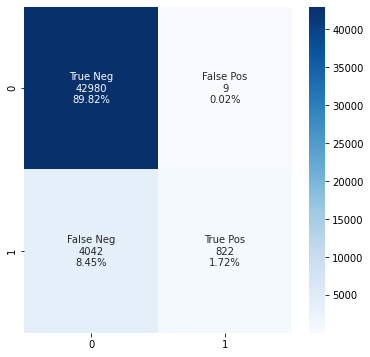

              precision    recall  f1-score   support

           0       0.91      1.00      0.95     42989
           1       0.99      0.17      0.29      4864

    accuracy                           0.92     47853
   macro avg       0.95      0.58      0.62     47853
weighted avg       0.92      0.92      0.89     47853



In [35]:
# Naive Bayes
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

mnb = MultinomialNB(alpha=1)
mnb.fit(tv_train_features, train_bad_comment)
mnb_tv_pred = mnb.predict(tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,mnb_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
plt.show()

print(classification_report(test_bad_comment,mnb_tv_pred))

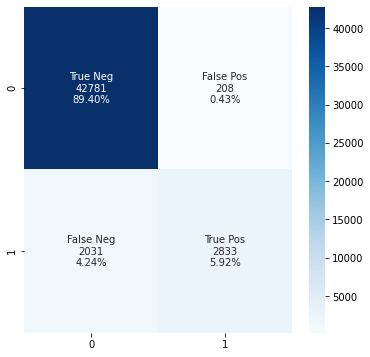

              precision    recall  f1-score   support

           0       0.95      1.00      0.97     42989
           1       0.93      0.58      0.72      4864

    accuracy                           0.95     47853
   macro avg       0.94      0.79      0.85     47853
weighted avg       0.95      0.95      0.95     47853



In [36]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(penalty='l2',max_iter=100, C=1, random_state=42)
lr.fit(tv_train_features, train_bad_comment)
lr_tv_pred = lr.predict(tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,lr_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
plt.show()

print(classification_report(test_bad_comment,lr_tv_pred))

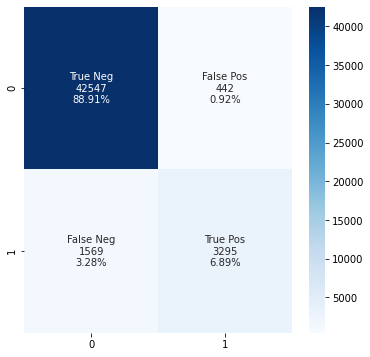

              precision    recall  f1-score   support

           0       0.96      0.99      0.98     42989
           1       0.88      0.68      0.77      4864

    accuracy                           0.96     47853
   macro avg       0.92      0.83      0.87     47853
weighted avg       0.96      0.96      0.96     47853



In [38]:
from sklearn.svm import LinearSVC
svm = LinearSVC(penalty='l2', C=1, random_state=42)
svm.fit(tv_train_features, train_bad_comment)
svm_tv_pred =svm.predict(tv_test_features)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(test_bad_comment,svm_tv_pred)

group_names = ['True Neg','False Pos','False Neg','True Pos']

group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
plt.show()

print(classification_report(test_bad_comment,svm_tv_pred))